<a href="https://colab.research.google.com/github/Jabbiks/ML/blob/main/%D0%9B%D0%A0_11_%D0%90%D0%B2%D1%80%D0%B0%D0%BC%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Імпорт бібліотек та завантаження датасету з Kaggle

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

keras.utils.set_random_seed(42)
sns.set_style("whitegrid")

# Завантаження набору даних GTSRB з Kaggle
dataset_path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Шлях до датасету:", dataset_path)
print("Файли в корені:", os.listdir(dataset_path))

train_df = pd.read_csv(os.path.join(dataset_path, "Train.csv"))
test_df = pd.read_csv(os.path.join(dataset_path, "Test.csv"))

print(f"\nКількість навчальних зображень (Train.csv): {len(train_df)}")
print(f"Кількість тестових зображень (Test.csv):    {len(test_df)}")
print(f"Кількість унікальних класів:               {train_df['ClassId'].nunique()}")
display(train_df.head())

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Шлях до датасету: /kaggle/input/gtsrb-german-traffic-sign
Файли в корені: ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']

Кількість навчальних зображень (Train.csv): 39209
Кількість тестових зображень (Test.csv):    12630
Кількість унікальних класів:               43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


2. Аналіз розподілу класів та візуалізація прикладів знаків

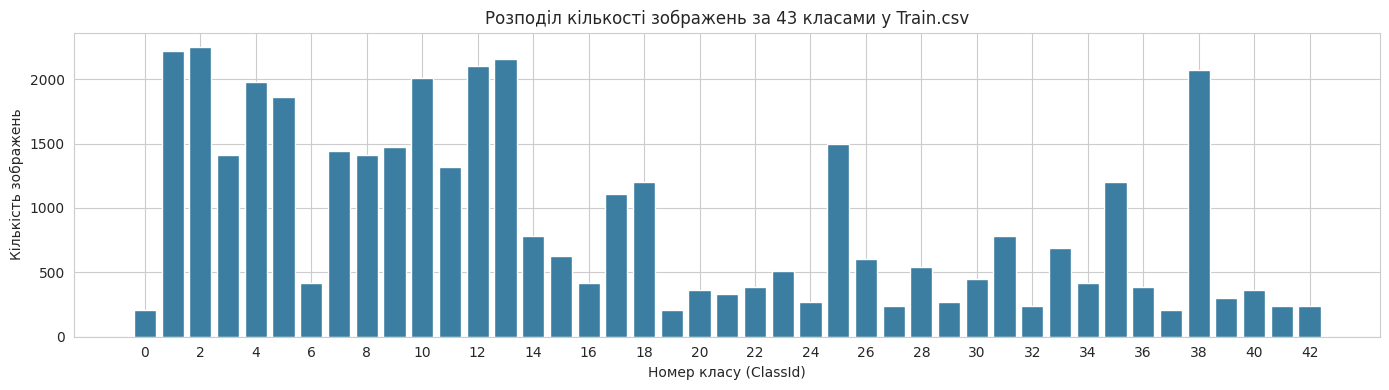

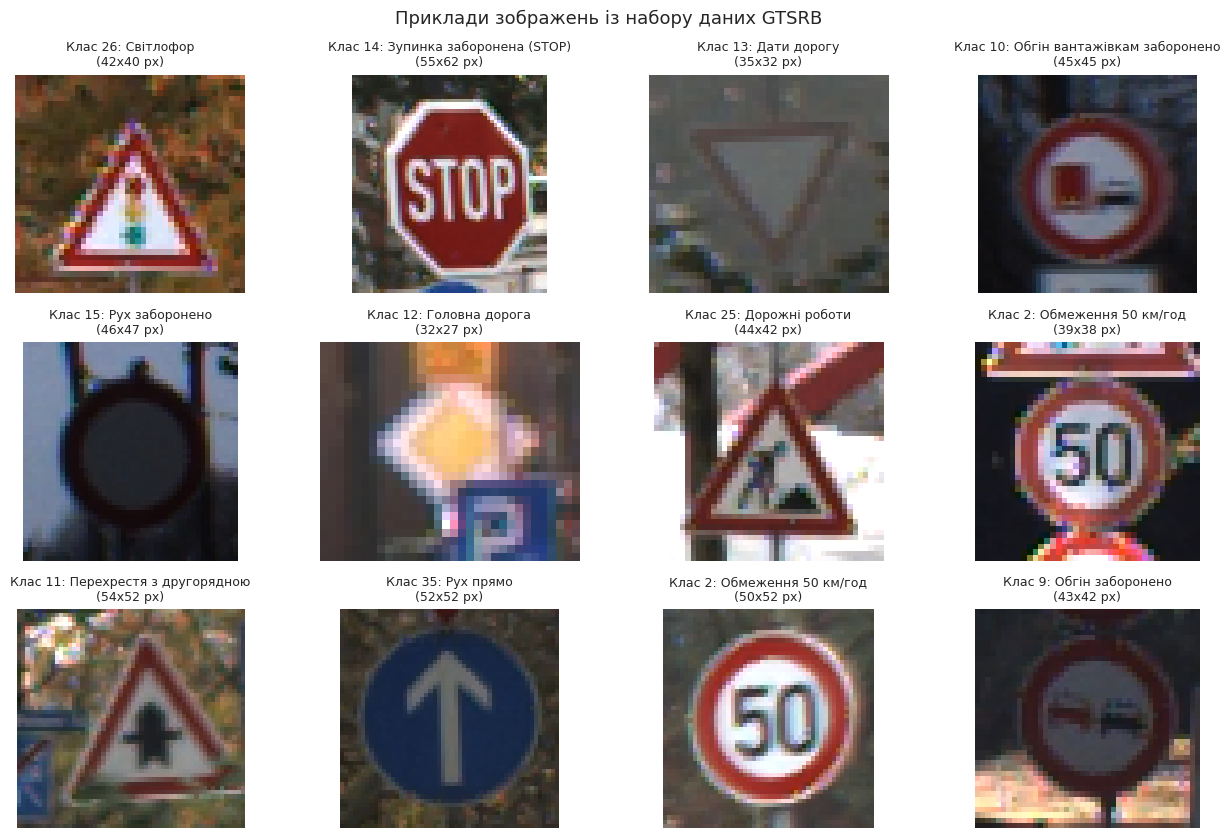

In [2]:
# Словник назв 43 класів дорожніх знаків GTSRB
CLASS_NAMES = {
    0: "Обмеження 20 км/год", 1: "Обмеження 30 км/год", 2: "Обмеження 50 км/год",
    3: "Обмеження 60 км/год", 4: "Обмеження 70 км/год", 5: "Обмеження 80 км/год",
    6: "Кінець обмеження 80 км/год", 7: "Обмеження 100 км/год", 8: "Обмеження 120 км/год",
    9: "Обгін заборонено", 10: "Обгін вантажівкам заборонено", 11: "Перехрестя з другорядною",
    12: "Головна дорога", 13: "Дати дорогу", 14: "Зупинка заборонена (STOP)",
    15: "Рух заборонено", 16: "Рух вантажівок заборонено", 17: "В'їзд заборонено",
    18: "Інша небезпека", 19: "Небезпечний поворот ліворуч", 20: "Небезпечний поворот праворуч",
    21: "Декілька поворотів", 22: "Нерівна дорога", 23: "Слизька дорога",
    24: "Звуження дороги праворуч", 25: "Дорожні роботи", 26: "Світлофор",
    27: "Пішохідний перехід", 28: "Діти", 29: "Велосипедисти",
    30: "Ожеледиця / сніг", 31: "Дикі тварини", 32: "Кінець усіх обмежень",
    33: "Поворот праворуч", 34: "Поворот ліворуч", 35: "Рух прямо",
    36: "Рух прямо або праворуч", 37: "Рух прямо або ліворуч", 38: "Об'їзд перешкоди справа",
    39: "Об'їзд перешкоди зліва", 40: "Круговий рух", 41: "Кінець заборони обгону",
    42: "Кінець заборони обгону вантажівкам"
}

# 1. Графік розподілу зображень за класами у навчальному наборі
plt.figure(figsize=(14, 4))
class_counts = train_df["ClassId"].value_counts().sort_index()
plt.bar(class_counts.index, class_counts.values, color="#3b7ea1")
plt.title("Розподіл кількості зображень за 43 класами у Train.csv")
plt.xlabel("Номер класу (ClassId)")
plt.ylabel("Кількість зображень")
plt.xticks(range(0, 43, 2))
plt.tight_layout()
plt.show()

# 2. Виведення 12 випадкових зображень дорожніх знаків із підписами класів
sample_rows = train_df.sample(12, random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(13, 8.5))

for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    img_path = os.path.join(dataset_path, row["Path"])
    img = Image.open(img_path)
    cls_id = int(row["ClassId"])
    ax.imshow(img)
    ax.set_title(f"Клас {cls_id}: {CLASS_NAMES[cls_id]}\n({img.size[0]}x{img.size[1]} px)", fontsize=9)
    ax.axis("off")

plt.suptitle("Приклади зображень із набору даних GTSRB", fontsize=13)
plt.tight_layout()
plt.show()

3. Підготовка зображень та поділ на вибірки

In [3]:
IMG_SIZE = 32
NUM_CLASSES = 43

def load_images_from_df(df, root_dir, img_size=IMG_SIZE):
    images = np.empty((len(df), img_size, img_size, 3), dtype=np.float32)
    labels = df["ClassId"].to_numpy(dtype=np.int64)
    for idx, rel_path in enumerate(df["Path"]):
        full_path = os.path.join(root_dir, rel_path)
        with Image.open(full_path) as img:
            img_resized = img.convert("RGB").resize((img_size, img_size), Image.Resampling.BILINEAR)
            images[idx] = np.asarray(img_resized, dtype=np.float32) / 255.0
    return images, labels

print("Завантаження та масштабування зображень до 32x32...")
X_full, y_full = load_images_from_df(train_df, dataset_path, IMG_SIZE)
X_test, y_test = load_images_from_df(test_df, dataset_path, IMG_SIZE)

# Ділимо Train.csv на навчальну (80%) та валідаційну (20%) вибірки зі збереженням пропорцій класів
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.20, random_state=42, stratify=y_full
)

print(f"Навчальна вибірка (X_train):   {X_train.shape}, мітки: {y_train.shape}")
print(f"Валідаційна вибірка (X_val):   {X_val.shape}, мітки: {y_val.shape}")
print(f"Тестова вибірка (X_test):      {X_test.shape}, мітки: {y_test.shape}")

Завантаження та масштабування зображень до 32x32...
Навчальна вибірка (X_train):   (31367, 32, 32, 3), мітки: (31367,)
Валідаційна вибірка (X_val):   (7842, 32, 32, 3), мітки: (7842,)
Тестова вибірка (X_test):      (12630, 32, 32, 3), мітки: (12630,)


4. Підбір архітектури згорткової нейронної мережі

Порівняємо дві архітектури на валідаційній вибірці, щоб обґрунтовано обрати найкращу модель:

CNN_Simple — компактна мережа з двома одиночними згортковими блоками (32 -> 64 фільтри).

CNN_Deep_BN — поглиблена архітектура з двома подвійними згортковими блоками (32, 32 та 64, 64 фільтри), шарами BatchNormalization та регуляризацією Dropout.

In [4]:
def build_cnn_simple(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    model = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(num_classes, activation="softmax")
    ], name="CNN_Simple")
    return model


def build_cnn_deep_bn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    model = keras.Sequential([
        keras.Input(shape=input_shape),

        # Блок 1: виділення базових контурів та кольорових меж
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Блок 2: виділення складніших символів усередині знаку
        layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Класифікатор
        layers.Flatten(),
        layers.Dense(256, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.50),
        layers.Dense(num_classes, activation="softmax")
    ], name="CNN_Deep_BN")
    return model


candidates = {
    "CNN_Simple": build_cnn_simple(),
    "CNN_Deep_BN": build_cnn_deep_bn()
}

histories = {}
arch_results = []

for name, net in candidates.items():
    print(f"\n{'='*55}\nНавчання архітектури: {name} (параметрів: {net.count_params():,})\n{'='*55}")
    net.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
    lr_sched = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)

    hist = net.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=64,
        callbacks=[es, lr_sched],
        verbose=1
    )
    histories[name] = hist
    val_loss, val_acc = net.evaluate(X_val, y_val, verbose=0)
    arch_results.append({
        "Архітектура": name,
        "Параметрів": net.count_params(),
        "Епох виконано": len(hist.history["loss"]),
        "Val Loss": round(val_loss, 4),
        "Val Accuracy (%)": round(val_acc * 100, 2)
    })

arch_df = pd.DataFrame(arch_results).sort_values(by="Val Accuracy (%)", ascending=False).reset_index(drop=True)
print("\nПорівняння кандидатів архітектур на валідаційній вибірці:")
display(arch_df)

best_arch_name = arch_df.loc[0, "Архітектура"]
best_model = candidates[best_arch_name]
best_history = histories[best_arch_name]
print(f"\nОбрана найкраща архітектура: {best_arch_name}")
best_model.summary()


Навчання архітектури: CNN_Simple (параметрів: 549,355)
Epoch 1/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.5194 - loss: 1.7173 - val_accuracy: 0.8796 - val_loss: 0.4887 - learning_rate: 0.0010
Epoch 2/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8712 - loss: 0.4271 - val_accuracy: 0.9538 - val_loss: 0.1804 - learning_rate: 0.0010
Epoch 3/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9319 - loss: 0.2291 - val_accuracy: 0.9773 - val_loss: 0.1002 - learning_rate: 0.0010
Epoch 4/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9521 - loss: 0.1619 - val_accuracy: 0.9786 - val_loss: 0.0831 - learning_rate: 0.0010
Epoch 5/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9659 - loss: 0.1146 - val_accuracy: 0.9871 - val_loss: 0.0570 - learning_rate: 0.0010
Epoch 6/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9719 - loss: 0.0913 - val_accuracy: 0.9904 - val_loss: 0.0483 - learning_rate: 0.0010
Epoch 7/15
491/491 ━━━━━━━━━━━

,Архітектура,Параметрів,Епох виконано,Val Loss,Val Accuracy (%)
0,CNN_Deep_BN,1126795,15,0.0058,99.87
1,CNN_Simple,549355,15,0.0338,99.41



Обрана найкраща архітектура: CNN_Deep_BN


Model: "CNN_Deep_BN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 3,378,595 (12.89 MB)

 Trainable params: 1,125,899 (4.29 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 2,251,800 (8.59 MB)

5. Криві навчання найкращої моделі

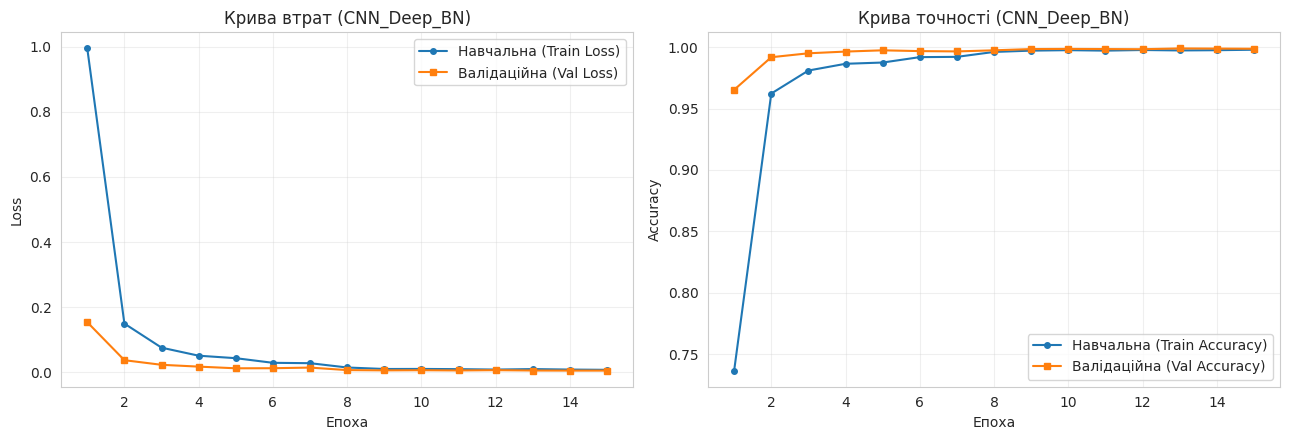

In [5]:
epochs_range = np.arange(1, len(best_history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Крива втрат
axes[0].plot(epochs_range, best_history.history["loss"], marker="o", ms=4, label="Навчальна (Train Loss)")
axes[0].plot(epochs_range, best_history.history["val_loss"], marker="s", ms=4, label="Валідаційна (Val Loss)")
axes[0].set_title(f"Крива втрат ({best_arch_name})")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Крива точності
axes[1].plot(epochs_range, best_history.history["accuracy"], marker="o", ms=4, label="Навчальна (Train Accuracy)")
axes[1].plot(epochs_range, best_history.history["val_accuracy"], marker="s", ms=4, label="Валідаційна (Val Accuracy)")
axes[1].set_title(f"Крива точності ({best_arch_name})")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

6. Оцінювання на тестовій вибірці та візуалізація класифікації

Тестові втрати (Test Loss):     0.0515
Тестова точність (Test Acc):    98.52% (12443 із 12630)

Найчастіші помилки класифікації на тестовому наборі:
  Справжній: [26] Світлофор  -->  Прогноз: [20] Небезпечний поворот праворуч (13 разів)
  Справжній: [12] Головна дорога  -->  Прогноз: [15] Рух заборонено (12 разів)
  Справжній: [6] Кінець обмеження 80 км/год  -->  Прогноз: [32] Кінець усіх обмежень (10 разів)
  Справжній: [3] Обмеження 60 км/год  -->  Прогноз: [5] Обмеження 80 км/год (10 разів)
  Справжній: [25] Дорожні роботи  -->  Прогноз: [11] Перехрестя з другорядною (7 разів)


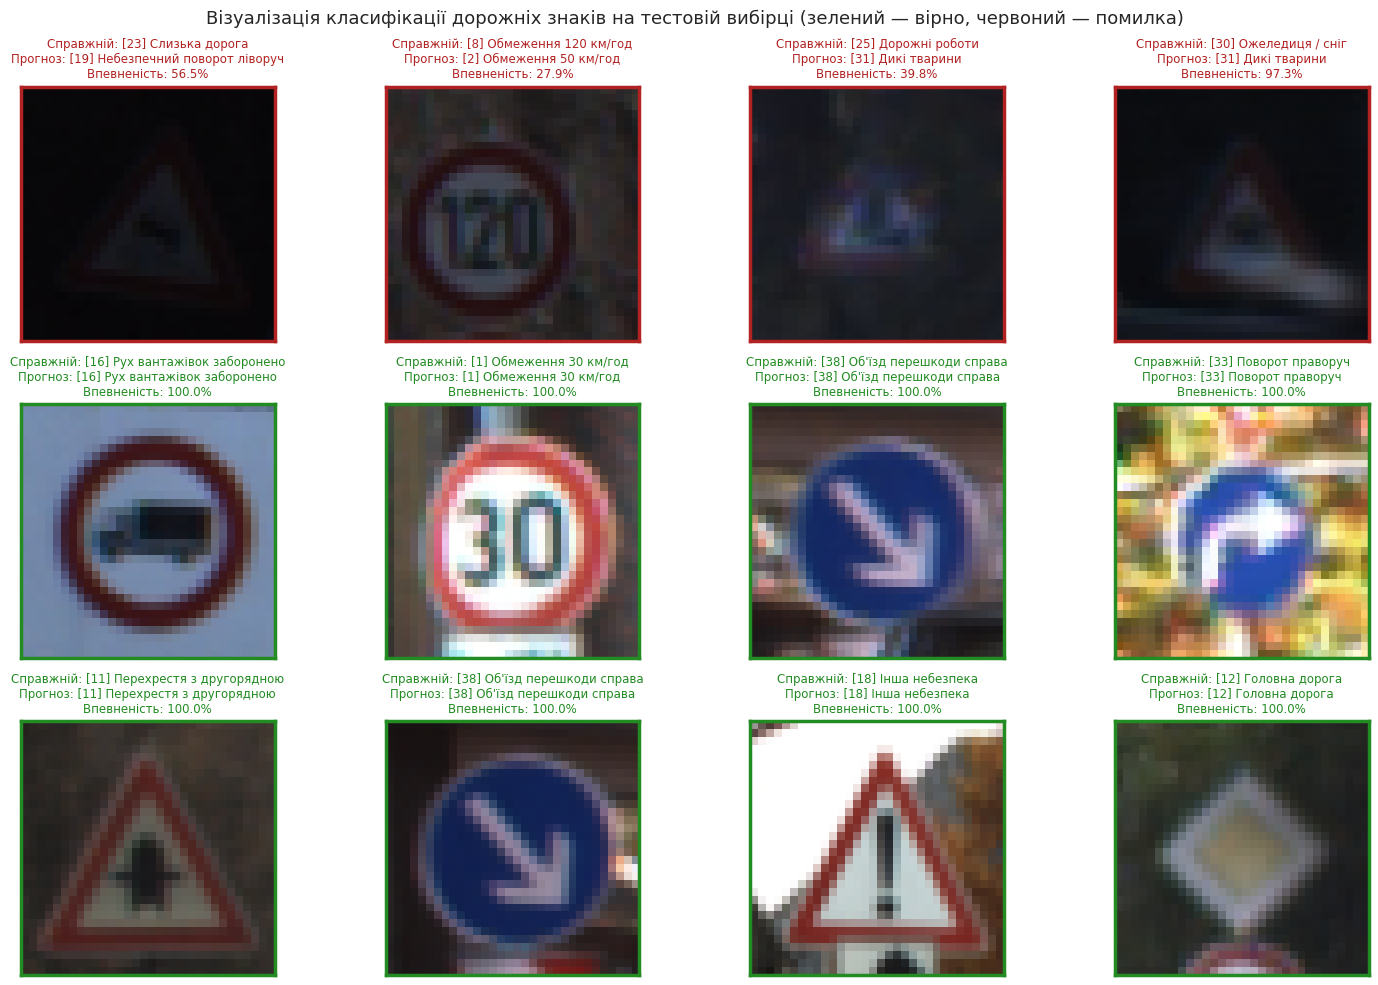

In [6]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
y_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_probs, axis=1)
y_conf = y_probs.max(axis=1)

print(f"Тестові втрати (Test Loss):     {test_loss:.4f}")
print(f"Тестова точність (Test Acc):    {test_acc:.2%} ({(y_pred == y_test).sum()} із {len(y_test)})")

# Знайдемо 5 найчастіших пар помилок у матриці невідповідностей
cm = confusion_matrix(y_test, y_pred)
np.fill_diagonal(cm, 0)
top_pairs = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1], cm.shape))[0][:5]

print("\nНайчастіші помилки класифікації на тестовому наборі:")
for true_c, pred_c in top_pairs:
    if cm[true_c, pred_c] > 0:
        print(f"  Справжній: [{true_c}] {CLASS_NAMES[true_c]}  -->  Прогноз: [{pred_c}] {CLASS_NAMES[pred_c]} ({cm[true_c, pred_c]} разів)")

# Візуалізація класифікації (картинка, справжній та прогнозований клас)
# Покажемо 4 помилкові приклади (за наявності) та 8 правильних
wrong_idx = np.flatnonzero(y_pred != y_test)
correct_idx = np.flatnonzero(y_pred == y_test)
vis_indices = list(wrong_idx[:4]) + list(correct_idx[:12 - len(wrong_idx[:4])])

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, idx in zip(axes.flat, vis_indices):
    is_correct = (y_pred[idx] == y_test[idx])
    color = "forestgreen" if is_correct else "firebrick"

    ax.imshow(X_test[idx])
    ax.set_title(
        f"Справжній: [{y_test[idx]}] {CLASS_NAMES[y_test[idx]]}\n"
        f"Прогноз: [{y_pred[idx]}] {CLASS_NAMES[y_pred[idx]]}\n"
        f"Впевненість: {y_conf[idx]:.1%}",
        color=color,
        fontsize=8.5
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(2.5)

plt.suptitle("Візуалізація класифікації дорожніх знаків на тестовій вибірці (зелений — вірно, червоний — помилка)", fontsize=13)
plt.tight_layout()
plt.show()

###7. Висновки

Для розпізнавання дорожніх знаків я взяв датасет GTSRB із Kaggle на 43 класи, привів усі картинки до єдиного розміру $32 \times 32$ пікселі та поділив дані на тренувальну (31 367 зображень), валідаційну (7 842) і тестову (12 630) вибірки. Під час перегляду набору стало помітно, що класи незбалансовані — в одних є понад дві тисячі прикладів, а в інших близько двохсот. Серед двох протестованих архітектур краще спрацювала глибша мережа CNN_Deep_BN із шарами BatchNormalization та Dropout: на валідації вона дала 99,87% точності проти 99,41% у простішої CNN_Simple. Криві навчання показують, що модель швидко сходиться вже за перші 3–4 епохи, а навчальна й валідаційна криві далі йдуть майже поруч, тож перенавчання немає. На тестовій вибірці мережа правильно визначила 12 443 знаки з 12 630, показавши точність 98,52% і втрати 0,0515. На візуалізації видно, що чіткі знаки розпізнаються зі стовідсотковою впевненістю, а поодинокі помилки трапляються здебільшого на занадто темних або розмитих фото та між схожими за формою знаками (наприклад, коли «Світлофор» плутається з небезпечним поворотом або «Обмеження 60» з «80»).